Dataset Preview:
    EMG Label
0  0.10  Rest
1  0.15  Rest
2  0.20  Rest
3  0.50  Flex
4  0.60  Flex

Converted Labels:
    EMG  Label
0  0.10      0
1  0.15      0
2  0.20      0
3  0.50      1
4  0.60      1


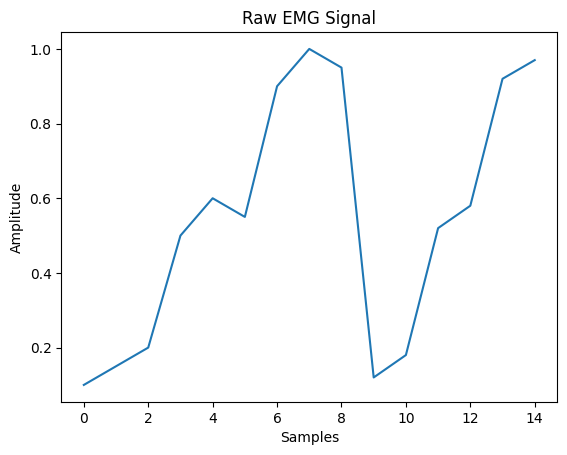

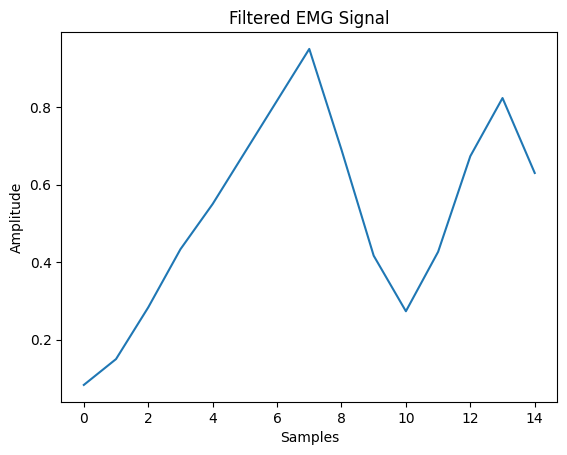


Feature Shape: (12, 3)

Model Accuracy: 0.6666666666666666

Predicted Activity: Grip

Confusion Matrix:
 [[1 0 0]
 [0 1 1]
 [0 0 0]]

EMG Signal Classification Completed Successfully 🚀


In [1]:
# ==============================
# EMG SIGNAL CLASSIFICATION PROJECT
# ==============================

# 1. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# ==============================
# 2. Load Dataset
# ==============================
data = pd.read_csv("../data/emg_data.csv")

print("Dataset Preview:")
print(data.head())

# ==============================
# 3. Convert Labels to Numbers
# ==============================
label_map = {
    "Rest": 0,
    "Flex": 1,
    "Grip": 2
}

data['Label'] = data['Label'].map(label_map)

print("\nConverted Labels:")
print(data.head())

# ==============================
# 4. Visualize Raw EMG Signal
# ==============================
plt.figure()
plt.plot(data['EMG'])
plt.title("Raw EMG Signal")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.show()

# ==============================
# 5. Apply Filtering (Moving Average)
# ==============================
def moving_average(signal, window_size=3):
    return np.convolve(signal, np.ones(window_size)/window_size, mode='same')

data['Filtered'] = moving_average(data['EMG'])

plt.figure()
plt.plot(data['Filtered'])
plt.title("Filtered EMG Signal")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.show()

# ==============================
# 6. Feature Extraction
# ==============================
def extract_features(signal, labels):
    features = []
    new_labels = []
    window_size = 3

    for i in range(0, len(signal) - window_size):
        window = signal[i:i+window_size]

        mean = np.mean(window)
        rms = np.sqrt(np.mean(window**2))
        variance = np.var(window)

        features.append([mean, rms, variance])
        new_labels.append(labels.iloc[i])

    return np.array(features), np.array(new_labels)

X, y = extract_features(data['Filtered'], data['Label'])

print("\nFeature Shape:", X.shape)

# ==============================
# 7. Train ML Model
# ==============================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", accuracy)

# ==============================
# 8. Test Prediction
# ==============================
sample = X_test[0].reshape(1, -1)
prediction = model.predict(sample)

reverse_map = {0: "Rest", 1: "Flex", 2: "Grip"}

print("\nPredicted Activity:", reverse_map[prediction[0]])

# ==============================
# 9. Confusion Matrix
# ==============================
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:\n", cm)

# ==============================
# 10. Final Output Message
# ==============================
print("\nEMG Signal Classification Completed Successfully 🚀")

In [ ]:
import pandas as pd

data = pd.read_csv("../data/EMG-data.csv")

print(data.head())
print(data.columns)

   time  channel1  channel2  channel3  channel4  channel5  channel6  channel7  \
0     1   0.00001  -0.00002  -0.00001  -0.00003   0.00000  -0.00001   0.00000   
1     5   0.00001  -0.00002  -0.00001  -0.00003   0.00000  -0.00001   0.00000   
2     6  -0.00001   0.00001   0.00002   0.00000   0.00001  -0.00002  -0.00001   
3     7  -0.00001   0.00001   0.00002   0.00000   0.00001  -0.00002  -0.00001   
4     8  -0.00001   0.00001   0.00002   0.00000   0.00001  -0.00002  -0.00001   

   channel8  class  label  
0  -0.00001      0      1  
1  -0.00001      0      1  
2   0.00001      0      1  
3   0.00001      0      1  
4   0.00001      0      1  
Index(['time', 'channel1', 'channel2', 'channel3', 'channel4', 'channel5',
       'channel6', 'channel7', 'channel8', 'class', 'label'],
      dtype='object')
